In [1]:
import os
import pandas as pd
import scanpy as ad
import matplotlib.pyplot as plt
from pathlib import Path

import numpy as np
import matplotlib.image as mpimg
from scipy.ndimage import rotate

import sys 
sys.path.append('/root/capsule/code/figures') 
from spatial_embedding_utils import plot_spatial_slice
from core_utils import get_seaad_colors

# Spatial Transcriptomics Subclass Plotting

This notebook creates spatial slice plots colored by subclass:
- **Overlay plot**: Single slice with all subclasses overlaid (small dots, each cell colored by subclass)
- **Tiled plot**: One panel per subclass (original style)

## Setup

In [2]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'spatial_transcriptomics'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')
spatial_slice_file = DATA_ROOT / 'human' / 'spatial' / '20250711' / 'H1930002Cx46MTG202007105_subset_section_qcd.h5ad'


In [3]:
# Load data
spatial_slice_data = ad.read_h5ad(spatial_slice_file)

/opt/conda/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


## Subclass Colors

In [4]:
# Define your subclasses and colors
subclasses = [
    'L2/3 IT',
    'L4 IT',
    'L5 IT',
    'L5/6 NP',
    'L5 ET',
    'L6 IT Car3',
    'L6 IT',
    'L6 CT',
    'L6b',
]

# Use subclass colors
color_dict = get_seaad_colors()

## Plot: Tiled View (Original Style)

Each subclass in its own panel for comparison.

/opt/conda/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


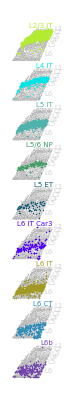

In [5]:
# Original tiled plot (one panel per subclass)
# Trick: Copy the subclass column to what the function expects
spatial_slice_data_tiled = spatial_slice_data.copy()
spatial_slice_data_tiled.obs['SEAAD_Supertype_name'] = spatial_slice_data.obs['SEAAD_Subclass_name']

fig, ax = plt.subplots(figsize=(20, 5))
plot_spatial_slice(spatial_slice_data_tiled, ax, subclasses, color_dict, rot_deg=221)
plt.show()

## Overlay Plotting Function

Custom function to plot all subclasses on a single slice with no tiling.

In [19]:

def plot_spatial_slice_overlay(data, ax, color_dict, group_col='SEAAD_Subclass_name', 
                                rot_deg=0, label_layers=True, 
                                overlay_layers=False, overlay_path=None,
                                plot_only_colored=False, subclasses_to_plot=None):
    """
    Plot spatial transcriptomics data with all groups overlaid in one slice.
    
    Parameters
    ----------
    data : AnnData
        Spatial transcriptomics data with spatial coordinates in data.obsm['spatial_cirro']
    ax : matplotlib.axes.Axes
        Axis to plot on
    color_dict : dict
        Mapping of groups to colors
    group_col : str
        Column name in data.obs containing group labels (default='SEAAD_Subclass_name')
    rot_deg : float, optional
        Rotation angle in degrees (default=0)
    label_layers : bool, optional
        If True, add cortical layer labels (default=True)
    overlay_layers : bool, optional
        If True, overlay layer boundary image (default=False)
    overlay_path : str, optional
        Path to layer boundary overlay image
    plot_only_colored : bool, optional
        If True, only plot groups that have defined colors (default=False)
        If False, plots all cells with undefined groups in grey
    subclasses_to_plot : list, optional
        List of specific subclasses to plot (e.g., ['L2/3 IT', 'L4 IT'])
        If None, plots all subclasses (subject to plot_only_colored filter)
    """
    layer_label_formatting_dict = {
        'L1': [250, 200],
        'L2': [50, 700],
        'L3': [-200, 1400],
        'L4': [-500, 1950],
        'L5': [-750, 2600],
        'L6': [-1300, 4000]
    }
    
    if overlay_layers and overlay_path:
        overlay = mpimg.imread(overlay_path)
        overlay_rotated = np.flipud(rotate(overlay, angle=rot_deg))
    
    # Slice rotation (degrees ccw)
    theta = np.deg2rad(rot_deg)
    rotation_matrix = np.array([
        [np.cos(theta), np.sin(theta)],
        [-np.sin(theta), np.cos(theta)]
    ])
    
    xmin = min(data.obsm['spatial_cirro'] @ rotation_matrix.T[:, 0])
    xmax = max(data.obsm['spatial_cirro'] @ rotation_matrix.T[:, 0])
    
    ymin = min(data.obsm['spatial_cirro'] @ rotation_matrix.T[:, 1])
    ymax = max(data.obsm['spatial_cirro'] @ rotation_matrix.T[:, 1])
    
    if overlay_layers and overlay_path:
        # Overlay layer lines
        overlay_ymin = ymin - 1800
        overlay_ymax = ymax + 1300
        overlay_xmin = xmin - 300
        overlay_xmax = xmax + 1300
        ax.imshow(
            overlay_rotated,
            extent=[overlay_xmin, overlay_xmax, overlay_ymin, overlay_ymax],
            aspect='auto',
            alpha=1,
            zorder=10,
            interpolation='none'
        )
    
    # Plot all cells once, colored by their group
    coords_rotated = data.obsm['spatial_cirro'] @ rotation_matrix.T
    
    # Separate groups into colored and grey (background)
    groups_to_plot = []
    grey_groups = []
    
    for group in data.obs[group_col].unique():
        if pd.isna(group):
            continue
        
        # Check if this group should be plotted
        if subclasses_to_plot is not None and group not in subclasses_to_plot:
            if not plot_only_colored:
                grey_groups.append(group)
            continue
        
        # Check if group has a defined color
        if group in color_dict:
            groups_to_plot.append(group)
        else:
            if not plot_only_colored:
                grey_groups.append(group)
    
    # Plot grey (background) groups first
    for group in grey_groups:
        group_mask = data.obs[group_col] == group
        group_coords = coords_rotated[group_mask]
        
        ax.scatter(
            group_coords[:, 0],
            group_coords[:, 1],
            c='#b9b9b9',
            alpha=1,
            s=10,
            marker='.',
            rasterized=True,
            linewidths=0
        )
    
    # Plot colored groups on top
    for group in groups_to_plot:
        group_mask = data.obs[group_col] == group
        group_coords = coords_rotated[group_mask]
        
        color = color_dict[group]
        
        ax.scatter(
            group_coords[:, 0],
            group_coords[:, 1],
            c=color,
            alpha=1,
            s=25,
            # marker='.',
            rasterized=True,
            linewidths=0
        )
    
    # Add layer labels
    if label_layers:
        right_edge = xmax
        top_edge = ymax
        for layer_label, [layer_x, layer_y] in layer_label_formatting_dict.items():
            ax.text(right_edge + layer_x, top_edge - layer_y, layer_label,
                   color='lightgrey', fontsize=20, ha='left', va='top')
    
    ax.axis('off')
    ax.set_aspect('equal')

## Plot: Single Overlay Slice

All subclasses plotted on one slice in their respective colors.

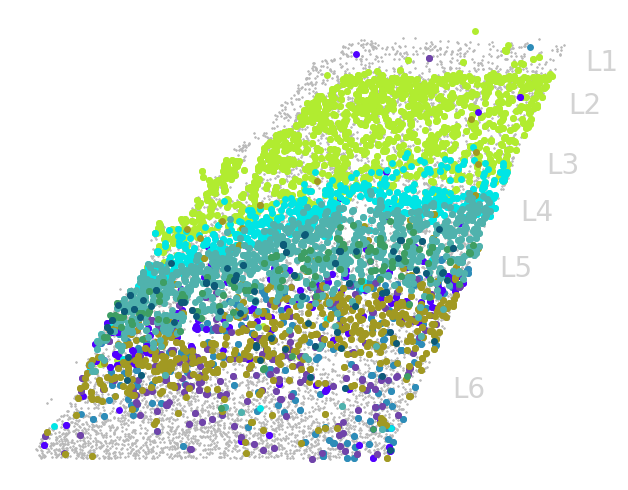

In [20]:
# Plot single slice with all subclasses overlaid
fig, ax = plt.subplots(figsize=(10, 5))
plot_spatial_slice_overlay(
    spatial_slice_data, 
    ax, 
    color_dict, 
    group_col='SEAAD_Subclass_name',
    rot_deg=221,
    label_layers=True,
)
plt.tight_layout()
fig.savefig(OUT_DIR / 'subclass.pdf', bbox_inches='tight')
plt.show()

## Plot: Subset of Subclasses

Example: Plot only specific subclasses of interest.

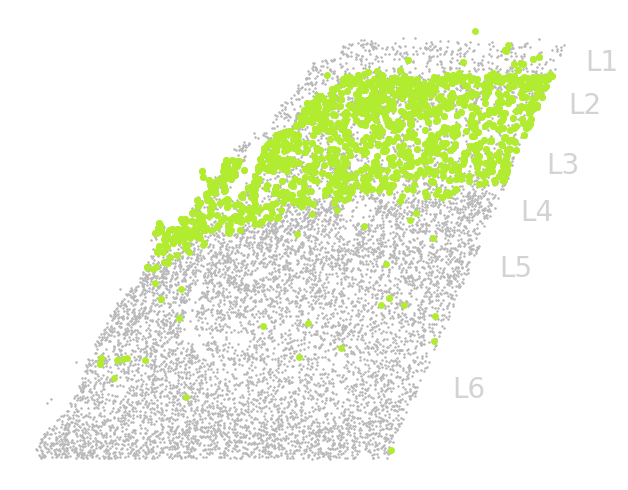

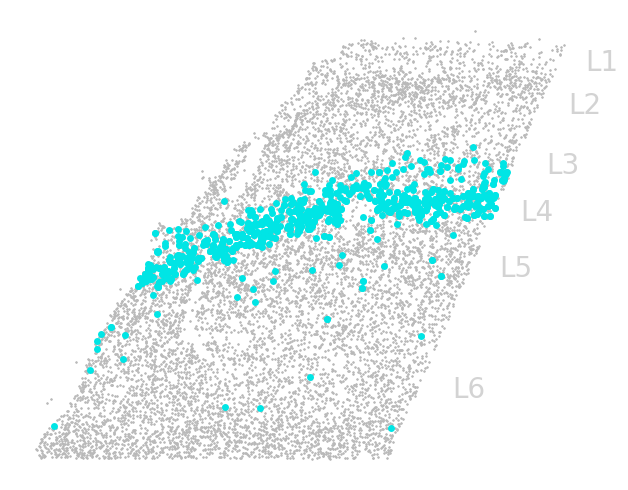

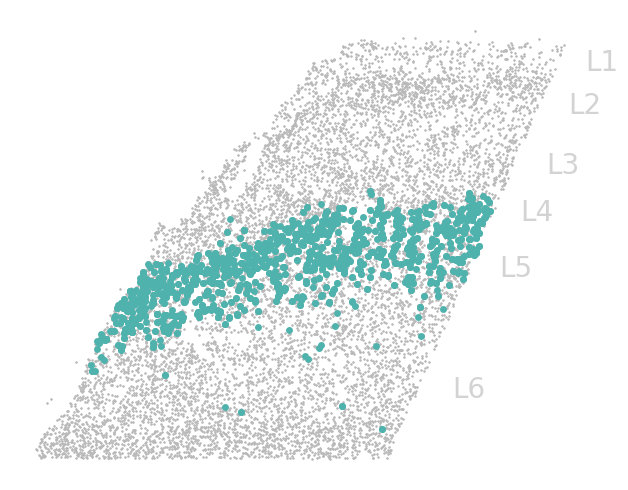

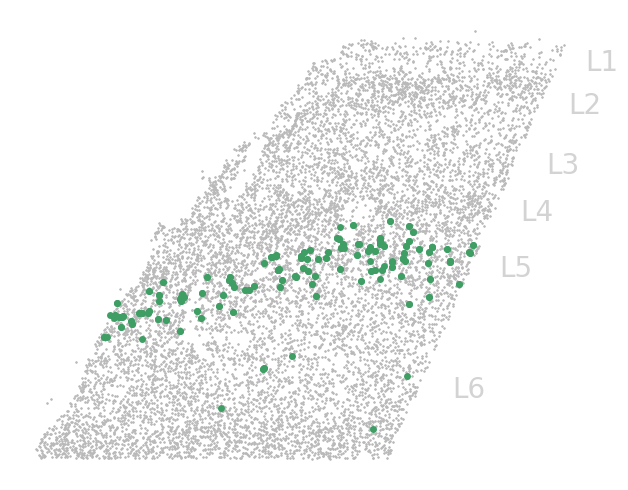

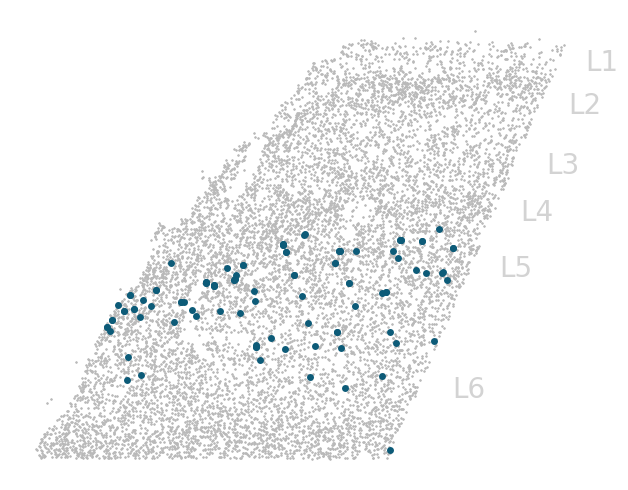

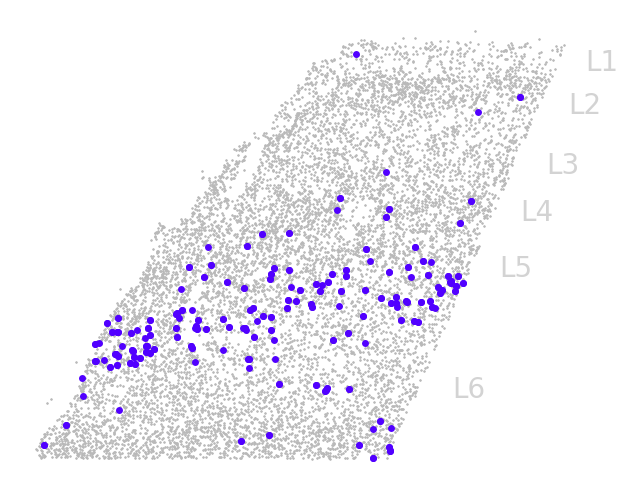

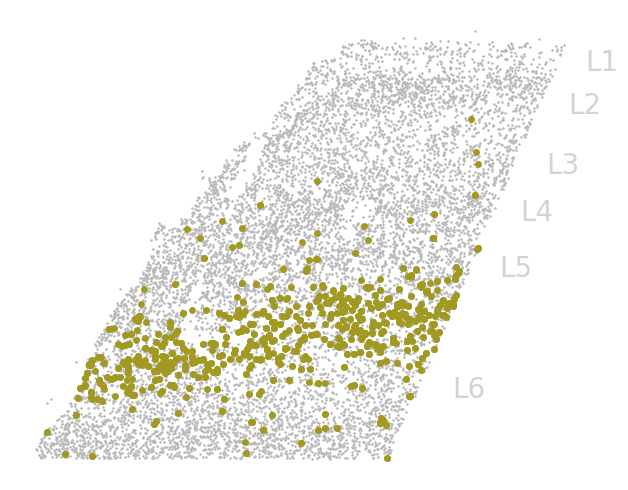

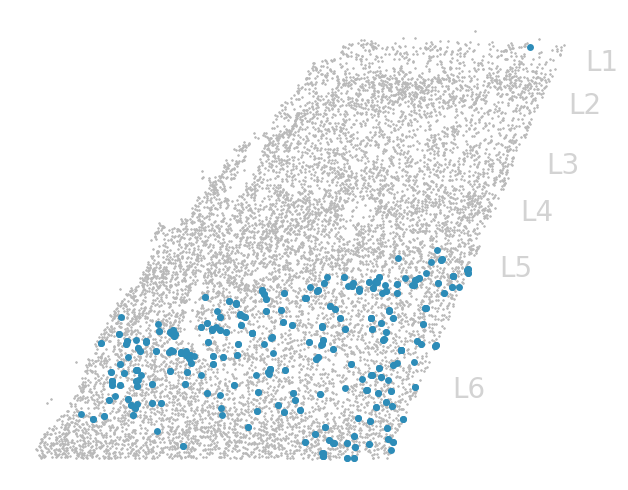

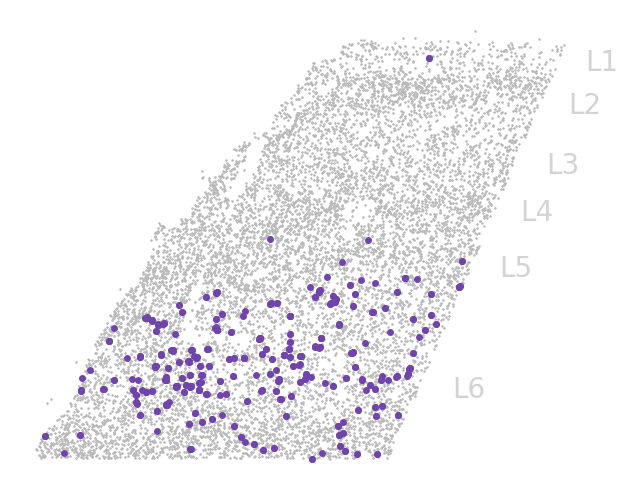

In [21]:
for subclass in subclasses:

    # Plot single slice with all subclasses overlaid
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_spatial_slice_overlay(
        spatial_slice_data, 
        ax, 
        color_dict, 
        group_col='SEAAD_Subclass_name',
        rot_deg=221,
        label_layers=True,
        subclasses_to_plot=[subclass]
    )
    plt.tight_layout()
    fig.savefig(OUT_DIR / '{}.pdf'.format(subclass.replace('/','-',).replace(' ', '_')), bbox_inches='tight')
    plt.show()